# NE 630 — Where does the simple depletion model break down?

We will hold the flux and its three-group shape fixed, then change the depletion model one assumption at a time. The question is not whether we can solve the resulting ODEs accurately. It is whether those ODEs, cross sections, and neutron-balance approximations retain the physics we need.

The module uses **FNRP Table 3.2**. The U-238 resonance correction is from **Chapter 4**. Supplementary decay data and reduced fission-product yields are identified in `README.md`; they are not entries in Table 3.2.

Three model levels are available: **(1)** constant U-238 and instantaneous breeding, **(2)** depleting U-238 and instantaneous breeding, and **(3)** the table-supported actinide chains with precursor delays and explicit poisons. “All” here means the supported teaching chain, not a complete depletion library.

In [1]:
%matplotlib inline

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ne630_depletion import (
    DAY, YEAR, BARN, LETHARGY_WIDTH, DEFAULT_PWR_SPECTRUM, TABLE32,
    UO2Shielding, Cell, three_group_xs, condense, xs_rows,
    uo2_initial, b10_from_ppm, build_chain, build_matrix,
    solve_depletion,
)

# These are adjustable teaching inputs, not a validated PWR benchmark.
TOTAL_FLUX = 2e14                    # n/cm^2/s, reference-flux convention below
SPECTRUM = (0.35, 0.55, 0.10)        # FAST, INTERMEDIATE, THERMAL integrated fractions
FUEL_DENSITY = 10.4                  # g UO2/cm^3
FUEL_DIAMETER = 0.82                 # cm
ENRICHMENT = 0.04                    # uranium mass fraction
DURATION_YEARS = 8
X_AXIS = "burnup"                    # "time", "fluence", or "burnup"
CLOSURE = "rate_ratio"               # or "four_factor"

shield = UO2Shielding(FUEL_DENSITY, FUEL_DIAMETER)
cell = Cell(moderator_to_fuel_volume=2.0, water_density_g_cm3=0.7,
            moderator_flux_ratios=(1.0, 1.0, 1.16))
fresh = uo2_initial(ENRICHMENT, FUEL_DENSITY)
xs3 = three_group_xs(shielding=shield)
xs1 = condense(xs3, SPECTRUM)
report_years = np.arange(6)           # initial state and years 1–5
times = np.unique(np.r_[report_years*YEAR, np.geomspace(60., 30*DAY, 80),
                        np.linspace(30*DAY, DURATION_YEARS*YEAR, 401)])
common = dict(time_s=times, total_flux=TOTAL_FLUX, initial=fresh,
              spectrum=SPECTRUM, xs3=xs3, cell=cell)
figdir = Path("figures")
figdir.mkdir(exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(figdir / (name + ".png"), dpi=160)
    plt.show()
    plt.close(fig)

## 1. Prepare the cross sections once; import them anywhere

The intermediate entries of Table 3.2 are **resonance integrals**, so

$$\bar\sigma_{xI}=\frac{I_x}{\ln(10^5)},\qquad
\bar\sigma_x=\sum_gw_g\bar\sigma_{xg}.$$

The default fractions are an illustrative PWR-like choice, not an OpenMC result. The microscopic thermal data remain the table's **293 K Maxwellian averages**, even though we use a lower moderator density.

For U-238 in UO₂, use $I_{\rm het}=4.45+26.6\sqrt{4/(\rho_fD)}$. This correlation does **not** supply shielding factors for the plutonium isotopes or gadolinium. Their uncorrected cross sections remain a known limitation.

The heterogeneous integral already includes the fuel/moderator resonance-flux depression. Consequently, the intermediate flux here is a **smooth reference flux**. Do not apply this correction again to reaction-rate-preserving cross sections condensed using a self-shielded transport spectrum.

In [2]:
print(f"U-238 empirical integral: {shield.integral_b():.4f} b")
print(f"Multiplier on Table 3.2 U-238 resonance integrals: {shield.integral_b()/278:.6f}")
print(f"Intermediate absorption: {xs3['U238'].absorption_b[1]:.4f} b")
print(f"Infinite-dilution value: {278/LETHARGY_WIDTH:.4f} b")

selected = ["U235", "U238", "Pu239", "Pu240", "Pu241", "Pu242",
            "B10", "Gd157", "Xe135", "Sm149"]
xs_table = pd.DataFrame(xs_rows(xs3, SPECTRUM)).set_index("nuclide")
display(xs_table.loc[selected].round(5))

# A notebook can use these scalars directly in its own equations.
sigma_a_235 = xs1["U235"].absorption_b
sigma_f_235 = xs1["U235"].fission_b
sigma_capture_238 = xs1["U238"].capture_b
print("U-235 one-group absorption / fission (b):", sigma_a_235, sigma_f_235)

U-238 empirical integral: 22.6675 b
Multiplier on Table 3.2 U-238 resonance integrals: 0.081538
Intermediate absorption: 1.9689 b
Infinite-dilution value: 24.1468 b


,sigma_aF_b,sigma_fF_b,sigma_aI_b,sigma_fI_b,sigma_aT_b,sigma_fT_b,sigma_a_b,sigma_f_b,sigma_c_b,nu_sigma_f_b
nuclide,,,,,,,,,,
U235,1.29000,1.220,35.09099,23.62562,591.00,505.00000,78.85155,63.92109,14.93046,155.32825
U238,0.36100,0.304,1.96887,0.00001,2.42,0.00001,1.45123,0.10641,1.34482,0.29794
Pu239,1.86000,1.810,41.17112,25.10222,973.00,698.00000,120.59511,84.23972,36.35539,244.29519
Pu240,1.42000,1.360,734.13139,0.32485,263.00,0.06130,430.56927,0.66080,429.90847,1.98240
Pu241,1.83000,1.620,64.27558,49.59643,1273.00,946.00000,163.29207,122.44504,40.84703,361.21286
Pu242,1.22000,1.140,97.02139,0.08165,16.60,0.01300,55.44876,0.44521,55.00356,1.33562
B10,0.49100,0.000,149.57102,0.00000,3409.00,0.00000,423.33591,0.00000,423.33591,0.00000
Gd157,0.20100,0.000,66.18648,0.00000,192000.00,0.00000,19236.47291,0.00000,19236.47291,0.00000
Xe135,0.00074,0.000,664.47056,0.00000,2640000.00,0.00000,264365.45907,0.00000,264365.45907,0.00000


U-235 one-group absorption / fission (b): 78.85154677578052 63.921090898545295


## 2. Build the chain before solving it

Each arrow is a `Transition`. A capture or fission rate contributes a loss to the parent's diagonal and production to its daughters. A beta decay does the same with $\lambda$ rather than $\phi\sigma$. The final matrix row integrates cumulative fissions.

For the two simple models,

$$\dot N_5=-\bar\sigma_{a5}\phi N_5,\qquad
\dot N_8=0\ \text{or}\ -\bar\sigma_{a8}\phi N_8,\qquad
\dot N_9=\bar\sigma_{\gamma8}\phi N_8-\bar\sigma_{a9}\phi N_9.$$

The expanded model follows U-239 and Np-239 before Pu-239 appears, and retains the subsequent Pu capture chain. `_sink` means a tracked terminal product whose further neutron reactions are **outside this data set**, not a physical claim of zero absorption.

In [3]:
for level in (1, 2, 3):
    print(build_chain(level).describe())
    print()

# Inspect the actual operator. The last row counts fissions/cm^3.
chain = build_chain(3)
A = build_matrix(chain, xs3, TOTAL_FLUX, SPECTRUM, cell)
print("Number of tracked species:", len(chain.nuclides))
print("Augmented matrix shape:", A.shape)

Model: constant_u238
Frozen external reservoirs: U238
U235     --capture   --> U236_sink
U238     --capture   --> Pu239 [instantaneous U239/Np239 beta decays]
Pu239    --capture   --> Pu240_sink [no further Pu capture chain]
U235     --fission   --> 2 FP_other_sink
U238     --fission   --> 2 FP_other_sink
Pu239    --fission   --> 2 FP_other_sink
Terminal/zero-XS bookkeeping sinks: U236_sink, Pu240_sink, FP_other_sink

Model: variable_u238
Frozen external reservoirs: none
U235     --capture   --> U236_sink
U238     --capture   --> Pu239 [instantaneous U239/Np239 beta decays]
Pu239    --capture   --> Pu240_sink [no further Pu capture chain]
U235     --fission   --> 2 FP_other_sink
U238     --fission   --> 2 FP_other_sink
Pu239    --fission   --> 2 FP_other_sink
Terminal/zero-XS bookkeeping sinks: U236_sink, Pu240_sink, FP_other_sink

Model: full
Frozen external reservoirs: none
U235     --capture   --> U236_sink
U238     --capture   --> U239
U239     --decay     --> Np239
Np239    --deca

## 3. Compare the models with the same irradiation inputs

The additional `3a` case turns off the explicit poisons while retaining the expanded actinide chain. This separates the effects of the actinides from Xe/Sm. There is no initial B-10 or Gd-157 loading in this first comparison.

For `rate_ratio`, $k$ is the production/absorption ratio **evaluated on the prescribed spectrum**, not a newly solved transport eigenvalue. We use $\rho=1-1/k$ without a near-critical approximation. Choose `four_factor` above to use the FNRP-style closure instead; we compare the closures separately below.

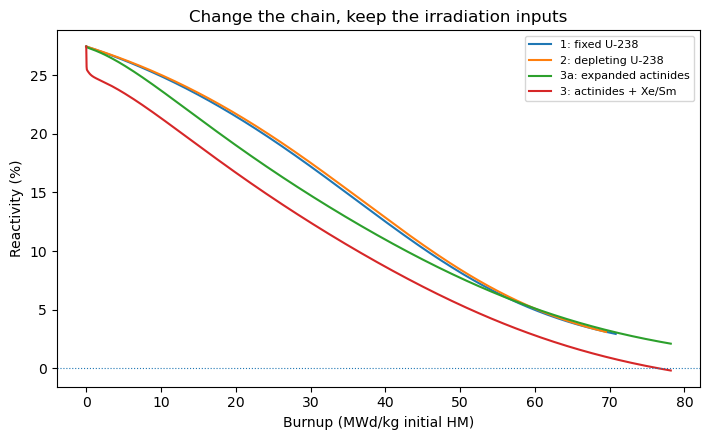

,burnup_MWd_kgHM,U238_fraction_remaining,Pu239_atoms_cm3,Pu239_fission_power_fraction,rho_rate_ratio,rho_four_factor,final_power_W_cm3
model,,,,,,,
1: fixed U-238,70.812846,1.000000,2.477503e+20,0.856728,0.029188,0.310531,156.119962
2: depleting U-238,69.528315,0.929345,2.330096e+20,0.855226,0.030857,0.321785,147.089052
3a: expanded actinides,78.176867,0.929345,2.330256e+20,0.675494,0.020864,0.356283,186.238538
3: actinides + Xe/Sm,78.176867,0.929345,2.330256e+20,0.675494,-0.002074,0.324593,186.238538


In [4]:
runs = {
    "1: fixed U-238": solve_depletion(**common, model=1),
    "2: depleting U-238": solve_depletion(**common, model=2),
    "3a: expanded actinides": solve_depletion(**common, model=3, include_poisons=False),
    "3: actinides + Xe/Sm": solve_depletion(**common, model=3),
}
full = runs["3: actinides + Xe/Sm"]

fig, ax = plt.subplots(figsize=(7.2, 4.5))
for label, result in runs.items():
    x, xlabel = result.axis(X_AXIS, "years")
    ax.plot(x, 100*result.neutronics(CLOSURE)["rho"], label=label)
ax.axhline(0, linestyle=":", linewidth=0.8)
ax.set(xlabel=xlabel, ylabel="Reactivity (%)", title="Change the chain, keep the irradiation inputs")
ax.legend(fontsize=8)
show(fig, "chain_comparison")

summary = pd.DataFrame([
    dict(model=label, burnup_MWd_kgHM=r.burnup_mwd_kg[-1],
         U238_fraction_remaining=r.density("U238")[-1]/r.density("U238")[0],
         Pu239_atoms_cm3=r.density("Pu239")[-1],
         Pu239_fission_power_fraction=r.fission_power_fraction("Pu239")[-1],
         rho_rate_ratio=r.neutronics("rate_ratio")["rho"][-1],
         rho_four_factor=r.neutronics("four_factor")["rho"][-1],
         final_power_W_cm3=r.power_density_w_cm3[-1])
    for label, r in runs.items()
]).set_index("model")
display(summary)
summary.to_csv("default_model_comparison.csv")

Allowing U-238 to decrease reduces both its production of Pu-239 **and** its neutron absorption. We should not assume in advance that this change always lowers reactivity. The answer also depends on the neutron-balance approximation.

Each curve has its **own** burnup coordinate. The same flux and elapsed time do not imply the same integrated fission energy.

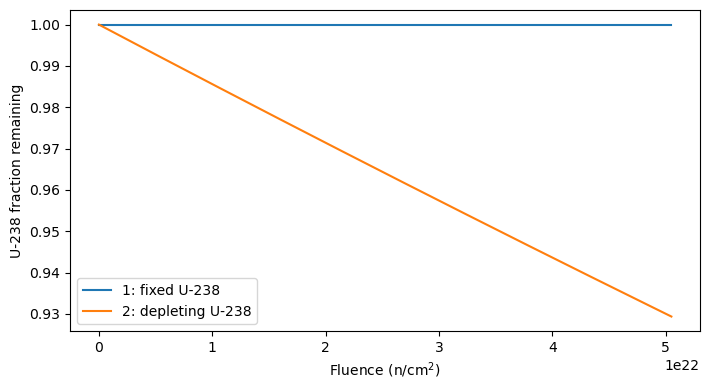

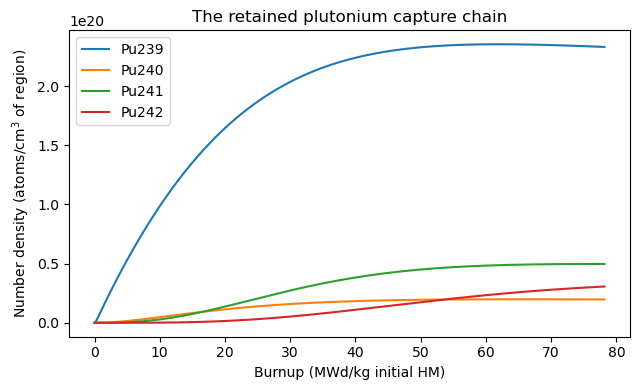

In [5]:
fig, ax = plt.subplots(figsize=(7.2, 4))
for label in ("1: fixed U-238", "2: depleting U-238"):
    r = runs[label]
    ax.plot(r.fluence_cm2, r.density("U238")/r.density("U238")[0], label=label)
ax.set(xlabel=r"Fluence (n/cm$^2$)", ylabel="U-238 fraction remaining")
ax.legend()
show(fig, "u238_inventory")

ax = full.plot(["Pu239", "Pu240", "Pu241", "Pu242"], x=X_AXIS, time_unit="years")
ax.set_title("The retained plutonium capture chain")
show(ax.figure, "plutonium_chain")

## 4. Use the depletion results to answer the handout questions

Use the module's data and the four cases already computed above to answer **Example — Parts 1 and 2** of the [Lesson 23 handout](../handouts/lesson_23_handout.tex). Model 1 corresponds to the handout's constant-U-238, instantaneous-breeding approximation; the other cases show how the answers change when we relax it.

The output grid includes years **0–5** exactly. Read number densities, Pu-239 power fractions, reactivity, fluence, burnup, and power directly from each `DepletionResult`. These calculations use the notebook's stated fuel, cross sections, geometry, and reactivity closures, so their numerical answers reflect those inputs rather than the handout's illustrative constants.

In [6]:
annual_inventories = {}
annual_results = {}
for label, result in runs.items():
    rows = np.searchsorted(result.time_s, report_years*YEAR)
    np.testing.assert_array_equal(result.time_s[rows], report_years*YEAR)
    index = pd.Index(report_years, name="year")

    # Part 1: number densities, in atoms/cm³ fuel, from the solved inventories.
    # Include the retained higher Pu isotopes and poisons when present.
    species = [name for name in ("U235", "U238", "Pu239", "Pu240", "Pu241", "Pu242", "Xe135", "Sm149")
               if name in result.nuclides]
    inventory = pd.DataFrame({name: result.density(name)[rows] for name in species}, index=index)
    annual_inventories[label] = inventory

    # Parts 1 and 2: all derived quantities come from the module.
    balance = result.neutronics(CLOSURE)
    annual = pd.DataFrame({
        "Pu239_power_fraction": result.fission_power_fraction("Pu239")[rows],
        "k": balance["k"][rows],
        "rho": balance["rho"][rows],
        "rho_percent": 100*balance["rho"][rows],
        "fluence_n_cm2": result.fluence_cm2[rows],
        "burnup_MWd_kg_initial_HM": result.burnup_mwd_kg[rows],
        "power_W_cm3_fuel": result.power_density_w_cm3[rows],
        "fission_rate_cm3_s": result.power_density_w_cm3[rows]/result.kappa_j,
    }, index=index)
    annual_results[label] = annual
    print(f"{label}: number densities (atoms/cm³ fuel)")
    display(inventory.style.format("{:.5e}"))
    print(f"{label}: annual results using {CLOSURE}")
    display(annual.style.format({
        "Pu239_power_fraction": "{:.3%}", "k": "{:.5f}", "rho": "{:.6f}",
        "rho_percent": "{:.3f}", "fluence_n_cm2": "{:.5e}",
        "burnup_MWd_kg_initial_HM": "{:.3f}", "power_W_cm3_fuel": "{:.3f}",
        "fission_rate_cm3_s": "{:.5e}",
    }))

1: fixed U-238: number densities (atoms/cm³ fuel)


,U235,U238,Pu239
year,,,
0,9.39644e+20,2.22672e+22,0.00000e+00
1,5.71251e+20,2.22672e+22,1.32318e+20
2,3.47288e+20,2.22672e+22,1.94128e+20
3,2.11132e+20,2.22672e+22,2.23001e+20
4,1.28356e+20,2.22672e+22,2.36489e+20
5,7.80333e+19,2.22672e+22,2.42790e+20


1: fixed U-238: annual results using rate_ratio


,Pu239_power_fraction,k,rho,rho_percent,fluence_n_cm2,burnup_MWd_kg_initial_HM,power_W_cm3_fuel,fission_rate_cm3_s
year,,,,,,,,
0,0.000%,1.37870,0.274681,27.468,0.00000e+00,0.000,400.111,1.24865e+13
1,22.279%,1.30853,0.235783,23.578,6.31152e+21,14.289,320.633,1.00062e+13
2,39.962%,1.23605,0.190969,19.097,1.26230e+22,25.834,262.255,8.18435e+12
3,54.214%,1.17204,0.146784,14.678,1.89346e+22,35.430,222.067,6.93015e+12
4,65.326%,1.12127,0.108152,10.815,2.52461e+22,43.711,195.439,6.09918e+12
5,73.544%,1.08405,0.077535,7.753,3.15576e+22,51.129,178.226,5.56199e+12


2: depleting U-238: number densities (atoms/cm³ fuel)


...

,Pu239_power_fraction,k,rho,rho_percent,fluence_n_cm2,burnup_MWd_kg_initial_HM,power_W_cm3_fuel,fission_rate_cm3_s
year,,,,,,,,
0,0.000%,1.37870,0.274681,27.468,0.00000e+00,0.000,400.111,1.24865e+13
1,21.730%,1.27684,0.216819,21.682,6.31152e+21,14.320,324.998,1.01424e+13
2,37.176%,1.19467,0.162950,16.295,1.26230e+22,26.268,278.177,8.68121e+12
3,47.812%,1.13859,0.121723,12.172,1.89346e+22,36.692,246.991,7.70800e+12
4,55.181%,1.09799,0.089247,8.925,2.52461e+22,46.075,225.280,7.03043e+12
5,60.273%,1.06824,0.063881,6.388,3.15576e+22,54.730,210.023,6.55431e+12


3: actinides + Xe/Sm: number densities (atoms/cm³ fuel)


,U235,U238,Pu239,Pu240,Pu241,Pu242,Xe135,Sm149
year,,,,,,,,
0,9.39644e+20,2.22672e+22,0.00000e+00,0.00000e+00,0.00000e+00,0.00000e+00,0.00000e+00,0.00000e+00
1,5.71251e+20,2.20642e+22,1.30816e+20,7.78669e+18,6.72947e+18,4.91199e+17,9.34651e+15,9.22089e+16
2,3.47288e+20,2.18630e+22,1.91557e+20,1.44668e+19,2.23179e+19,3.58680e+18,8.23162e+15,8.18122e+16
3,2.11132e+20,2.16637e+22,2.18742e+20,1.76942e+19,3.50897e+19,8.94521e+18,7.46189e+15,7.48544e+16
4,1.28356e+20,2.14661e+22,2.30263e+20,1.91158e+19,4.28500e+19,1.49117e+19,6.90560e+15,6.97888e+16
5,7.80333e+19,2.12704e+22,2.34477e+20,1.96818e+19,4.69265e+19,2.03502e+19,6.50231e+15,6.60464e+16


3: actinides + Xe/Sm: annual results using rate_ratio


,Pu239_power_fraction,k,rho,rho_percent,fluence_n_cm2,burnup_MWd_kg_initial_HM,power_W_cm3_fuel,fission_rate_cm3_s
year,,,,,,,,
0,0.000%,1.37870,0.274681,27.468,0.00000e+00,0.000,400.111,1.24865e+13
1,21.730%,1.23959,0.193279,19.328,6.31152e+21,14.320,324.998,1.01424e+13
2,37.176%,1.16226,0.139604,13.960,1.26230e+22,26.268,278.177,8.68121e+12
3,47.812%,1.10929,0.098522,9.852,1.89346e+22,36.692,246.991,7.70800e+12
4,55.181%,1.07083,0.066148,6.615,2.52461e+22,46.075,225.280,7.03043e+12
5,60.273%,1.04259,0.040851,4.085,3.15576e+22,54.730,210.023,6.55431e+12


### Initial reactivity and Pu-239 power after one year

The compact table answers the two individual questions from the handout. The Pu-239 value is its fraction of instantaneous fission power **at** one year, using the module's common energy per fission. The annual tables above provide the requested number densities, reactivities, fluences, and burnups after each of the five years.

In [7]:
handout_answers = pd.DataFrame({
    label: {
        "initial_rho": table.loc[0, "rho"],
        "initial_rho_percent": table.loc[0, "rho_percent"],
        "Pu239_power_fraction_at_1_year": table.loc[1, "Pu239_power_fraction"],
    }
    for label, table in annual_results.items()
}).T
handout_answers.index.name = "model"
display(handout_answers.style.format({
    "initial_rho": "{:.6f}", "initial_rho_percent": "{:.3f}",
    "Pu239_power_fraction_at_1_year": "{:.3%}",
}))
annual_inventory_table = pd.concat(annual_inventories, names=["model", "year"])
annual_results_table = pd.concat(annual_results, names=["model", "year"])
annual_inventory_table.to_csv("lesson_23_annual_number_densities.csv")
annual_results_table.to_csv("lesson_23_annual_results.csv")

,initial_rho,initial_rho_percent,Pu239_power_fraction_at_1_year
model,,,
1: fixed U-238,0.274681,27.468,22.279%
2: depleting U-238,0.274681,27.468,22.200%
3a: expanded actinides,0.274681,27.468,21.730%
3: actinides + Xe/Sm,0.274681,27.468,21.730%


### Ponderable: how does the fission rate change?

At fixed flux, evolving number densities change the fission rate and power. The module integrates this changing fission rate to compute burnup; burnup is therefore not generally proportional to time. Compare the annual fission rates and reactivities for the same four cases.

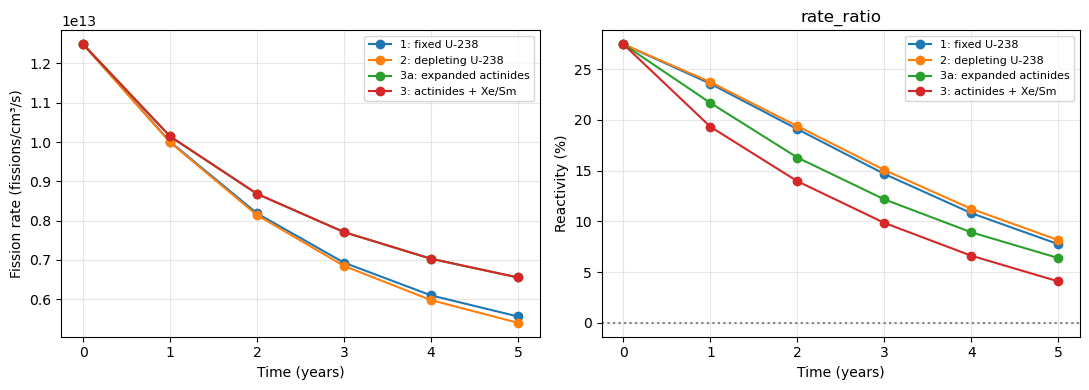

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, table in annual_results.items():
    axes[0].plot(report_years, table["fission_rate_cm3_s"], "o-", label=label)
    axes[1].plot(report_years, table["rho_percent"], "o-", label=label)
axes[0].set(xlabel="Time (years)", ylabel="Fission rate (fissions/cm³/s)")
axes[1].set(xlabel="Time (years)", ylabel="Reactivity (%)", title=CLOSURE)
axes[1].axhline(0, color="gray", linestyle=":")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
show(fig, "annual_fission_rate_and_reactivity")